In [28]:
# SIS 1 — Kitchen Products Data Analysis

## 1. Introduction

### Project Objective

To collect, clean, combine, and analyze kitchen product data from two different sources: DummyJSON API and IKEA website.

### Data Sources

1. DummyJSON API — Kitchen Accessories
2. IKEA Website — Dinnerware

### Tools

- Python
- Google Colab
- requests
- BeautifulSoup
- pandas
- Matplotlib

SyntaxError: invalid character '—' (U+2014) (4287453299.py, line 11)

In [29]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

In [30]:
import pandas as pd
import requests

url = "https://dummyjson.com/products/category/kitchen-accessories"

response = requests.get(url)
print(f"answer status: {response.status_code}")

data = response.json()

products = data["products"]

df = pd.DataFrame(products)

print(df.head())

answer status: 200
   id                title                                        description  \
0  48       Bamboo Spatula  The Bamboo Spatula is a versatile kitchen tool...   
1  49  Black Aluminium Cup  The Black Aluminium Cup is a stylish and durab...   
2  50          Black Whisk  The Black Whisk is a kitchen essential for whi...   
3  51        Boxed Blender  The Boxed Blender is a powerful and compact bl...   
4  52     Carbon Steel Wok  The Carbon Steel Wok is a versatile cooking pa...   

              category  price  discountPercentage  rating  stock  \
0  kitchen-accessories   7.99                2.84    3.27     37   
1  kitchen-accessories   5.99               15.65    4.46     75   
2  kitchen-accessories   9.99               10.24    3.90     73   
3  kitchen-accessories  39.99                7.26    4.56      9   
4  kitchen-accessories  29.99                6.53    4.05     40   

                             tags              sku  ...  \
0       [kitchen tools, ut

In [33]:
# 1. Number of rows and columns
print("--- DataFrame Shape (Rows, Columns) ---")
print(df.shape)

# 2. Names of all columns
print("\n--- Column Names ---")
print(df.columns.tolist())

# 3. Data types and non-null counts
print("\n--- DataFrame Info ---")
df.info()
# 4. Number of missing values per column
print("\n--- Missing Values ---")
print(df.isnull().sum())

# 5. Number of duplicate rows
print("\n--- Duplicates ---")
print(f"Number of duplicate rows: {df.duplicated(subset=['id']).sum()}")

--- DataFrame Shape (Rows, Columns) ---
(30, 21)

--- Column Names ---
['id', 'title', 'description', 'category', 'price', 'discountPercentage', 'rating', 'stock', 'tags', 'sku', 'weight', 'dimensions', 'warrantyInformation', 'shippingInformation', 'availabilityStatus', 'reviews', 'returnPolicy', 'minimumOrderQuantity', 'meta', 'images', 'thumbnail']

--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    30 non-null     int64  
 1   title                 30 non-null     object 
 2   description           30 non-null     object 
 3   category              30 non-null     object 
 4   price                 30 non-null     float64
 5   discountPercentage    30 non-null     float64
 6   rating                30 non-null     float64
 7   stock                 30 non-null     int64  
 8   tags 

In [34]:
columns = [
    "id",
    "title",
    "category",
    "price",
    "discountPercentage",
    "rating",
    "stock",
    "availabilityStatus"
]

In [36]:
df_clean = df[columns].copy()
df_clean.dtypes

,0
id,int64
title,object
category,object
price,float64
discountPercentage,float64
rating,float64
stock,int64
availabilityStatus,object


In [40]:
df_clean = df[columns].copy()

# Rename columns: title -> product_name, discountPercentage -> discount, availabilityStatus -> availability
df_clean = df_clean.rename(
    columns={
        "title": "product_name",
        "discountPercentage": "discount",
        "availabilityStatus": "availability",
    }
)

# Check the new column names
print("--- Updated Column Names ---")
print(df_clean.columns.tolist())

--- Updated Column Names ---
['id', 'product_name', 'category', 'price', 'discount', 'rating', 'stock', 'availability']


In [38]:
print(df_clean.duplicated(subset=["id"]).sum())

0


In [39]:
display(df_clean.head())
print(df_clean.shape)

,id,product_name,description,category,price,discount,rating,stock,tags,sku,...,dimensions,warrantyInformation,shippingInformation,availability,reviews,returnPolicy,minimumOrderQuantity,meta,images,thumbnail
0,48,Bamboo Spatula,The Bamboo Spatula is a versatile kitchen tool...,kitchen-accessories,7.99,2.84,3.27,37,"[kitchen tools, utensils]",KIT-BRD-BAM-048,...,"{'width': 21.32, 'height': 23.03, 'depth': 25.94}",1 month warranty,Ships overnight,In Stock,"[{'rating': 5, 'comment': 'Awesome product!', ...",60 days return policy,29,"{'createdAt': '2024-11-07T19:26:12.737Z', 'upd...",[https://cdn.dummyjson.com/product-images/kitc...,https://cdn.dummyjson.com/product-images/kitch...
1,49,Black Aluminium Cup,The Black Aluminium Cup is a stylish and durab...,kitchen-accessories,5.99,15.65,4.46,75,"[drinkware, cups]",KIT-BRD-BLA-049,...,"{'width': 5.88, 'height': 5.11, 'depth': 10.03}",1 year warranty,Ships overnight,In Stock,"[{'rating': 3, 'comment': 'Very disappointed!'...",30 days return policy,48,"{'createdAt': '2025-06-02T20:54:31.793Z', 'upd...",[https://cdn.dummyjson.com/product-images/kitc...,https://cdn.dummyjson.com/product-images/kitch...
2,50,Black Whisk,The Black Whisk is a kitchen essential for whi...,kitchen-accessories,9.99,10.24,3.90,73,"[kitchen tools, utensils]",KIT-BRD-BLA-050,...,"{'width': 13.03, 'height': 5.99, 'depth': 20.64}",3 months warranty,Ships in 1 month,In Stock,"[{'rating': 3, 'comment': 'Not worth the price...",30 days return policy,40,"{'createdAt': '2024-09-26T11:34:05.709Z', 'upd...",[https://cdn.dummyjson.com/product-images/kitc...,https://cdn.dummyjson.com/product-images/kitch...
3,51,Boxed Blender,The Boxed Blender is a powerful and compact bl...,kitchen-accessories,39.99,7.26,4.56,9,"[kitchen appliances, blenders]",KIT-BRD-BOX-051,...,"{'width': 9.05, 'height': 19.45, 'depth': 17.59}",5 year warranty,Ships in 1-2 business days,In Stock,"[{'rating': 5, 'comment': 'Very pleased!', 'da...",7 days return policy,4,"{'createdAt': '2026-03-25T03:55:56.058Z', 'upd...",[https://cdn.dummyjson.com/product-images/kitc...,https://cdn.dummyjson.com/product-images/kitch...
4,52,Carbon Steel Wok,The Carbon Steel Wok is a versatile cooking pa...,kitchen-accessories,29.99,6.53,4.05,40,"[cookware, woks]",KIT-BRD-CAR-052,...,"{'width': 27.69, 'height': 7.54, 'depth': 10.11}",2 year warranty,Ships in 1-2 business days,In Stock,"[{'rating': 4, 'comment': 'Excellent quality!'...",7 days return policy,9,"{'createdAt': '2026-02-12T14:27:24.989Z', 'upd...",[https://cdn.dummyjson.com/product-images/kitc...,https://cdn.dummyjson.com/product-images/kitch...


(30, 21)


In [41]:
from bs4 import BeautifulSoup
import requests

ikea_url = "https://www.ikea.com/us/en/cat/dinnerware-18860/"

response_ikea = requests.get(ikea_url, timeout=15)

print("Status code:", response_ikea.status_code)

Status code: 200


In [42]:
soup = BeautifulSoup(response_ikea.text, "html.parser")

print("Page title:", soup.title.get_text(strip=True) if soup.title else "Not found")
print("HTML length:", len(response_ikea.text))

Page title: Dinnerware - Sets of Plates and Bowls - IKEA
HTML length: 1256311


In [43]:
print("H2 elements:", len(soup.find_all("h2")))
print("H3 elements:", len(soup.find_all("h3")))

H2 elements: 13
H3 elements: 33


In [44]:
h3_elements = soup.find_all("h3")

for element in h3_elements[:10]:
    print(element.get_text(strip=True))

GLADELIG18-piece dinnerware set, blue
GLADELIGDeep plate/bowl, blue, 8 ½ "
VITABBORREPlate, green, 10 "
FÄRGKLARDeep plate/bowl, lilac, 9 "
FÄRGKLAR18-piece dinnerware set, light pink
GODMIDDAG18-piece dinnerware set, white
PELARKAKTUSDeep plate/bowl, green, 9 "
FÄRGKLARPlate, lilac, 10 "
IKEA 365+Bowl, rounded sides white, 6 "
GLADELIGBowl, blue, 5 ½ "


In [45]:
print(h3_elements[0].prettify()[:1500])

<h3 class="plp-text plp-typography-heading-xs">
 <span class="plp-price-module__name-decorator notranslate">
  <a aria-disabled="false" aria-label="GLADELIG, 18-piece dinnerware set, blue" class="plp-price-module__product-link plp-link" data-skapa="hyperlink@9.1.3" href="https://www.ikea.com/us/en/p/gladelig-18-piece-dinnerware-set-blue-80588685/">
   <span class="notranslate plp-price-module__product-name">
    GLADELIG
   </span>
  </a>
 </span>
 <span class="plp-text plp-typography-label-m plp-typography-regular plp-price-module__description">
  <span aria-hidden="true">
   18-piece dinnerware set, blue
  </span>
 </span>
</h3>



In [46]:
parent = h3_elements[0].parent

print(parent.prettify()[:3000])

<div class="plp-price-module__information">
 <h3 class="plp-text plp-typography-heading-xs">
  <span class="plp-price-module__name-decorator notranslate">
   <a aria-disabled="false" aria-label="GLADELIG, 18-piece dinnerware set, blue" class="plp-price-module__product-link plp-link" data-skapa="hyperlink@9.1.3" href="https://www.ikea.com/us/en/p/gladelig-18-piece-dinnerware-set-blue-80588685/">
    <span class="notranslate plp-price-module__product-name">
     GLADELIG
    </span>
   </a>
  </span>
  <span class="plp-text plp-typography-label-m plp-typography-regular plp-price-module__description">
   <span aria-hidden="true">
    18-piece dinnerware set, blue
   </span>
  </span>
 </h3>
</div>



In [47]:
grandparent = parent.parent

print(grandparent.prettify()[:4000])

<div class="plp-price-module plp-price-module--small plp-price-module--commercial-message-placeholder plp-price-module--none plp-typography-typescale-desktop" data-skapa="price-module@11.2.1">
 <div class="plp-price-module__information">
  <h3 class="plp-text plp-typography-heading-xs">
   <span class="plp-price-module__name-decorator notranslate">
    <a aria-disabled="false" aria-label="GLADELIG, 18-piece dinnerware set, blue" class="plp-price-module__product-link plp-link" data-skapa="hyperlink@9.1.3" href="https://www.ikea.com/us/en/p/gladelig-18-piece-dinnerware-set-blue-80588685/">
     <span class="notranslate plp-price-module__product-name">
      GLADELIG
     </span>
    </a>
   </span>
   <span class="plp-text plp-typography-label-m plp-typography-regular plp-price-module__description">
    <span aria-hidden="true">
     18-piece dinnerware set, blue
    </span>
   </span>
  </h3>
 </div>
 <div class="plp-price-module__price">
  <div class="plp-price-module__primary-currency

In [48]:
price_element = grandparent.find(
    "span", class_="plp-price__integer"
)

print("Product:", h3_elements[0].get_text(strip=True))
print("Price integer:", price_element.get_text(strip=True))

Product: GLADELIG18-piece dinnerware set, blue
Price integer: 79


In [49]:
decimal_element = grandparent.find(
    "span", class_="plp-price__decimal"
)

print(decimal_element.get_text(strip=True) if decimal_element else "No decimal")

.99


In [50]:
price = float("79" + ".99")
print(price)

79.99


In [51]:
integer_part = price_element.get_text(strip=True)
decimal_part = decimal_element.get_text(strip=True)

In [52]:

integer_part = price_element.get_text(strip=True)
decimal_part = decimal_element.get_text(strip=True)
price_str = integer_part + "." + decimal_part.lstrip(".")
price_value = float(price_str)

print(price_value)  #

79.99


In [53]:
from urllib.robotparser import RobotFileParser
import requests
from bs4 import BeautifulSoup


target_url = "https://www.ikea.com/us/en/cat/dinnerware-18865/"
robot_url = "https://www.ikea.com/robots.txt"
user_agent = "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"

rp = RobotFileParser()
rp.set_url(robot_url)
rp.read()

if rp.can_fetch(user_agent, target_url):
    print("Access allowed by robots.txt. Proceeding with scraping...\n")

    headers = {"User-Agent": user_agent}
    response = requests.get(target_url, headers=headers)

    if response.status_code == 200:
        soup = BeautifulSoup(response.text, "html.parser")


        print("Page successfully fetched and parsed!")
    else:
        print(f"Failed to load page. Status code: {response.status_code}")
else:
    print("Access denied by robots.txt for this User-Agent.")

Access allowed by robots.txt. Proceeding with scraping...

Page successfully fetched and parsed!


In [54]:
import pandas as pd

product_cards = soup.find_all("div", class_="plp-price-module")

print(f"Number of product cards found: {len(product_cards)}")


data = []

for card in product_cards:
    name_elem = card.find(class_="plp-price-module__product-name")
    desc_elem = card.find(class_="plp-price-module__description")
    int_elem = card.find(class_="plp-price__integer")
    dec_elem = card.find(class_="plp-price__decimal")

    product_name = name_elem.get_text(strip=True) if name_elem else None
    description = desc_elem.get_text(strip=True) if desc_elem else None

    price = None
    if int_elem:
        integer_part = int_elem.get_text(strip=True)
        decimal_part = dec_elem.get_text(strip=True) if dec_elem else "00"
        price = float(integer_part + "." + decimal_part.lstrip("."))

    data.append({
        "product_name": product_name,
        "description": description,
        "price": price,
        "source": "IKEA"
    })

df_ikea = pd.DataFrame(data)

print("\n--- IKEA Dataset Preview ---")
print(df_ikea.head())

Number of product cards found: 24

--- IKEA Dataset Preview ---
  product_name                             description  price source
0      FÖRNUFT  20-piece flatware set, stainless steel  12.99   IKEA
1    IKEA 365+  20-piece flatware set, stainless steel  29.99   IKEA
2    DOFTSKÖLD        20-piece flatware set, off-white  39.99   IKEA
3      MARTORP              Fork, stainless steel, 7 "   6.99   IKEA
4   PRAKTBOTIA  16-piece flatware set, stainless steel  14.99   IKEA


In [55]:

print("--- DataFrame Shape ---")
print(df_ikea.shape)

print("\n--- DataFrame Info ---")
print(df_ikea.info())

print("\n--- Missing Values ---")
print(df_ikea.isnull().sum())

print("\n--- Duplicate Rows ---")
print(f"Number of duplicates: {df_ikea.duplicated().sum()}")

print("\n--- Price Statistics ---")
print(df_ikea["price"].describe())


print("\n--- Price Data Type ---")
print(f"Data type of 'price' column: {df_ikea['price'].dtype}")

invalid_prices = df_ikea[df_ikea["price"] <= 0]
print(f"Number of zero or negative prices: {len(invalid_prices)}")

if not invalid_prices.empty:
    print("Warning: Found items with zero or negative prices!")
else:
    print("All prices are valid (> 0).")

--- DataFrame Shape ---
(24, 4)

--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_name  24 non-null     object 
 1   description   24 non-null     object 
 2   price         24 non-null     float64
 3   source        24 non-null     object 
dtypes: float64(1), object(3)
memory usage: 900.0+ bytes
None

--- Missing Values ---
product_name    0
description     0
price           0
source          0
dtype: int64

--- Duplicate Rows ---
Number of duplicates: 0

--- Price Statistics ---
count    24.000000
mean     33.615000
std      33.268097
min       2.990000
25%       6.990000
50%      17.490000
75%      59.990000
max      99.990000
Name: price, dtype: float64

--- Price Data Type ---
Data type of 'price' column: float64
Number of zero or negative prices: 0
All prices are valid (> 0).


In [61]:
import pandas as pd

# STEP 9.1 — Prepare DummyJSON
df_dummy_prepared = df_clean[["product_name", "price"]].copy()
# Standardize category name to use space instead of hyphen ("kitchen accessories")
df_dummy_prepared["category"] = "kitchen accessories"
df_dummy_prepared["source"] = "DummyJSON"

# STEP 9.2 — Prepare IKEA (with refined category logic)
def assign_ikea_category(description):
    if pd.isna(description):
        return "other"

    desc_lower = description.lower()

    # 1. First check for cutlery
    if any(keyword in desc_lower for keyword in ["cutlery", "fork", "knife", "spoon"]):
        return "cutlery"
    # 2. Then check for general dinnerware sets
    elif "set" in desc_lower:
        return "dinnerware sets"
    # 3. Check for specific plates and bowls
    elif any(keyword in desc_lower for keyword in ["plate", "bowl", "dish"]):
        return "plates & bowls"
    else:
        return "kitchen accessories"

df_ikea_prepared = df_ikea[["product_name", "price", "source"]].copy()
df_ikea_prepared["category"] = df_ikea["description"].apply(assign_ikea_category)

# STEP 9.3 — Combine Datasets
columns_order = ["product_name", "category", "price", "source"]
df_dummy_prepared = df_dummy_prepared[columns_order]
df_ikea_prepared = df_ikea_prepared[columns_order]

# Concatenate tables and reset index
df_combined = pd.concat([df_dummy_prepared, df_ikea_prepared], ignore_index=True)

# Verification
print("--- Combined Dataset Shape ---")
print(df_combined.shape)  # Expected: (54, 4)

print("\n--- Standardized Category Distribution ---")
print(df_combined["category"].value_counts())

print("\n--- Distribution by Source and Category ---")
print(pd.crosstab(df_combined["category"], df_combined["source"]))

--- Combined Dataset Shape ---
(54, 4)

--- Standardized Category Distribution ---
category
kitchen accessories    32
dinnerware sets        14
cutlery                 8
Name: count, dtype: int64

--- Distribution by Source and Category ---
source               DummyJSON  IKEA
category                            
cutlery                      0     8
dinnerware sets              0    14
kitchen accessories         30     2


In [62]:
import pandas as pd


price_stats = df_combined.groupby("source")["price"].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

print("--- Descriptive Statistics for Prices by Source ---")
print(price_stats)


numeric_columns = ["price", "rating", "discount", "stock"]

correlation_matrix = df_clean[numeric_columns].corr()

print("\n--- Correlation Matrix (DummyJSON) ---")
print(correlation_matrix)

--- Descriptive Statistics for Prices by Source ---
           count    mean  median   min    max        std
source                                                  
DummyJSON     30  17.690   10.49  3.99  89.99  18.291038
IKEA          24  33.615   17.49  2.99  99.99  33.268097

--- Correlation Matrix (DummyJSON) ---
             price    rating  discount     stock
price     1.000000  0.244384  0.107860 -0.077250
rating    0.244384  1.000000  0.092568 -0.121945
discount  0.107860  0.092568  1.000000  0.043810
stock    -0.077250 -0.121945  0.043810  1.000000


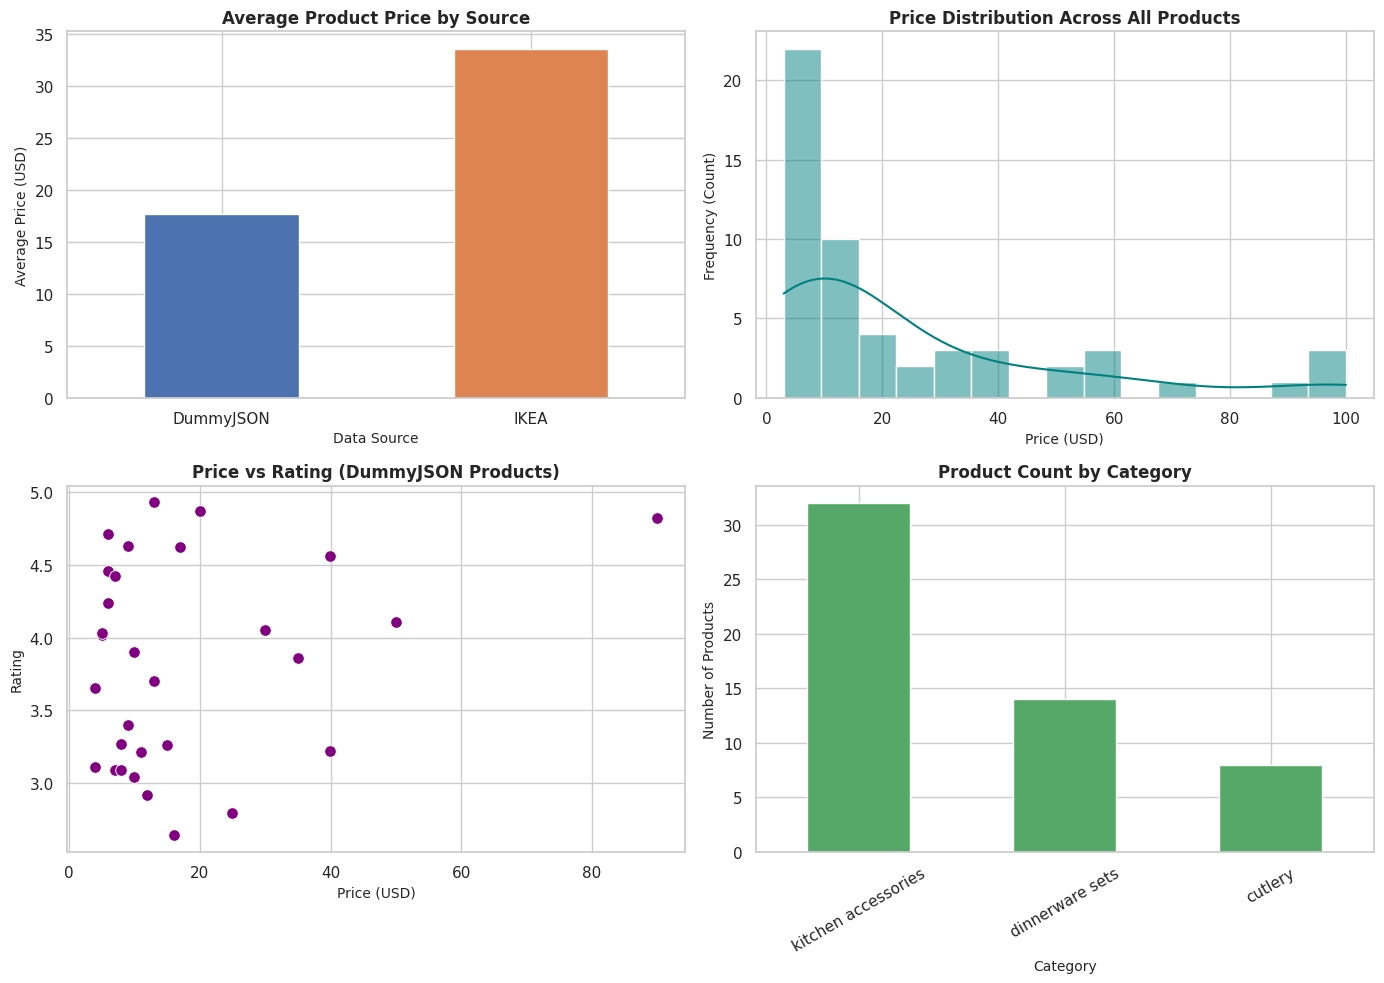

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

avg_prices = df_combined.groupby("source")["price"].mean()
avg_prices.plot(kind="bar", ax=axes[0, 0], color=["#4c72b0", "#dd8452"])

axes[0, 0].set_title("Average Product Price by Source", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Data Source", fontsize=10)
axes[0, 0].set_ylabel("Average Price (USD)", fontsize=10)
axes[0, 0].tick_params(axis="x", rotation=0)


sns.histplot(df_combined["price"], bins=15, kde=True, ax=axes[0, 1], color="teal")

axes[0, 1].set_title("Price Distribution Across All Products", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Price (USD)", fontsize=10)
axes[0, 1].set_ylabel("Frequency (Count)", fontsize=10)



sns.scatterplot(
    data=df_clean, x="price", y="rating", ax=axes[1, 0], color="purple", s=70
)

axes[1, 0].set_title("Price vs Rating (DummyJSON Products)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Price (USD)", fontsize=10)
axes[1, 0].set_ylabel("Rating", fontsize=10)


category_counts = df_combined["category"].value_counts()
category_counts.plot(kind="bar", ax=axes[1, 1], color="#55a868")

axes[1, 1].set_title("Product Count by Category", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Category", fontsize=10)
axes[1, 1].set_ylabel("Number of Products", fontsize=10)
axes[1, 1].tick_params(axis="x", rotation=30)


plt.tight_layout()
plt.show()